# Usage

## Installing Dependencies

If we are in Colab, we start by installing some dependencies. If not, please follow [the installation instructions](https://hri-eu.github.io/ProMis/installation.html).

In [1]:
def is_running_in_colab():
    try:
        import google.colab
        return True
    except ImportError:
        return False

if is_running_in_colab():
  !sudo apt-get update -qq
  !sudo apt-get install -yqq python3-gdal libgdal-dev
  !pip install -q promis

## Imports

Next, we import some of ProMis' core packages and third party dependencies.

In [2]:
# Probabilistic Mission Design and Statistical Relational Maps
from promis import ProMis, StaRMap
# Geographic data handling
from promis.geo import PolarLocation, CartesianMap, CartesianLocation, CartesianRasterBand, CartesianCollection
# Data loading from Overture Maps
from promis.loaders import OvertureLoader

# Third Party dependencies we will need
from numpy import eye
import matplotlib.pyplot as plt

## Uncertainty Annotated Maps

Probabilistic missions are built on an uncertainty aware environment representation we call Uncertainty Annotated Maps (UAM).
Here, to obtain a UAM, we use open map data from [Overture Maps](https://overturemaps.org) using ProMis' OvertureLoader class.
The OvertureLoader expects a feature description consisting of a location type that identifies the respective set of features and a 'filter' selecting the features.
A filter starts with the Overture type, e.g., `segment` for roads and railways, `land_use`, `water`, `building` or `place`, followed by optional conditions on the features' properties.
Nested properties are addressed with dotted keys, e.g., `place[taxonomy.primary=restaurant]`.

In [3]:
# The features we will load from Overture Maps
# The dictionary key will be stored as the respective features location_type
# The dictionary value is an Overture type followed by conditions on its properties
feature_description = {
    "park": "land_use[subtype=park][class=park]",
    "primary": "segment[subtype=road][class=primary]",
    "secondary": "segment[subtype=road][class=secondary]",
    "tertiary": "segment[subtype=road][class=tertiary]",
    "service": "segment[subtype=road][class=service]",
    "crossing": "segment[subtype=road][class=footway][subclass=crosswalk]",
    "bay": "water[class=bay]",
    "rail": "segment[subtype=rail][class=standard_gauge]",
}

Since we do not know how noisy the map data actually is, we define some noise ourselves for demonstration purposes.
In an actual application, you would insert your (neural) sensors and mapping modules' accuracy information here.

Here, the environment features will be assumed to be placed where we expect them with a random translation sampled from a Gaussian with one of the following covariance matrices.

In [4]:
# Covariance matrices for some of the features
# Used to draw random translations representing uncertainty for the respective features
covariance = {
    "primary": 15 * eye(2),
    "secondary": 10 * eye(2),
    "tertiary": 5 * eye(2),
    "service": 2.5 * eye(2),
    "operator": 20 * eye(2),
}

As a last piece of information before the UAM can be queried, we need to define the area in which our agent's mission will take place in.

In [5]:
# The mission area's origin in polar coordinates as well as area extends in meters
origin = PolarLocation(latitude=49.878091, longitude=8.654052)
width, height = 1000.0, 1000.0

Finally, we can load the relevant environment features.
The OvertureLoader downloads only the features within the mission area from Overture Maps, which takes a few seconds per Overture type.
We also apply our uncertainties in the data and place the position of the agent's operator at the center of the mission area.
The map data is © OpenStreetMap contributors and Overture Maps Foundation, licensed under [ODbL](https://opendatacommons.org/licenses/odbl/); the basemaps in the figures below are tiles from [OpenStreetMap](https://www.openstreetmap.org).

Maps, StaR Maps and landscapes can be stored with their `save(path)` method and restored with their class' `load(path)`, e.g., `uam.save("uam.pkl")` and `CartesianMap.load("uam.pkl")`.

In [6]:
# Setting up the Uncertainty Annotated Map from Overture Maps
uam = OvertureLoader(origin, (width, height), feature_description).to_cartesian_map()

# Adding the operator's location and applying out assumed levels of uncertainty
uam.features["operator"].append(CartesianLocation(0.0, 0.0, location_type="operator"))
uam.apply_covariance(covariance)

Now its time to consider what our actual mission requirements are and express them as a [Resin](https://github.com/simon-kohaut/resin) program. The full syntax and semantics are described in Resin's [language reference](https://github.com/simon-kohaut/resin/blob/main/docs/language.md); here is the gist.

Resin is a reactive probabilistic logic language where rules are written over spatial relation *sources*.
Each source declares a relation (e.g. `distance`, `over`) and a location type, along with whether it carries a bare `Probability` or a continuous `Density` (for which Resin evaluates the CDF at any threshold used in rule bodies).

Rules use `if` for disjunctive clauses and `and` for conjunction.
A final `-> target(...)` declaration names the output we want to query.
Comments start with `#`.

In [7]:
resin_program = """
# Spatial relation sources
over(park) <- source("/star_map/over/park", Probability).
over(bay) <- source("/star_map/over/bay", Probability).
distance(operator) <- source("/star_map/distance/operator", Density).
distance(service) <- source("/star_map/distance/service", Density).
distance(primary) <- source("/star_map/distance/primary", Density).
distance(secondary) <- source("/star_map/distance/secondary", Density).
distance(tertiary) <- source("/star_map/distance/tertiary", Density).
distance(rail) <- source("/star_map/distance/rail", Density).
distance(crossing) <- source("/star_map/distance/crossing", Density).

# Visual line of sight: within the operator's range, or over a bay at extended range
vlos if distance(operator) < 500.0.
vlos if over(bay) and distance(operator) < 400.0.

# Permits based on proximity to infrastructure or green space
permits if over(park).
permits if distance(service) < 15.0.
permits if distance(primary) < 15.0.
permits if distance(secondary) < 10.0.
permits if distance(tertiary) < 5.0.
permits if distance(rail) < 5.0.
permits if distance(crossing) < 5.0.

# A valid mission requires line of sight and local permits
landscape if vlos and permits.
landscape -> target("/landscape").
"""

Now its time to compute the StaR Map.
For this, we define some points in the mission area to compute the StaR Map for and initialize it for the rules we defined above.

In [8]:
# Setting up the probabilistic spatial relations from the UAM we previously computed
star_map = StaRMap(uam)

# Initializing the StaR Map on a raster of points evenly spaced out across the mission area,
# sampling 25 random variants of the UAM for estimating the spatial relation parameters.
# The Resin program determines which relations are needed.
evaluation_points = CartesianRasterBand(origin, (100, 100), width, height)
star_map.initialize(evaluation_points, number_of_random_maps=25, logic=resin_program)

Let's inspect the parameters of the StaR Map relations by visualizing the estimated values.
We do so by accessing the parameters (a `promis.geo.Collection` holding mean and variances for each sampled point), and interpolating to a more fine-granular grid over the mission area.

In [9]:
# Visualize the spatial relations with an OSM basemap in the background
def show_collection(collection, value_index, ax, title):
    # Fine-granular interpolation target for the spatial relations
    mission_area = CartesianRasterBand(collection.origin, (300, 300), width, height)

    image = collection.into(mission_area).scatter(value_index=value_index, ax=ax, s=0.4, plot_basemap=True, rasterized=True, cmap="coolwarm_r", alpha=0.25)
    cbar = plt.colorbar(image, aspect=18.5, fraction=0.05, pad=0.02)
    cbar.solids.set(alpha=1)
    ax.set_title(title)

def set_style(axes=None):
    if axes is None:
        axes = plt.gcf().axes
    # Set axes labeling
    ticks = [-width / 2.0, 0, width / 2.0]
    labels = ["0", "0.5", "1"]
    axes[0].set_ylabel("Northing / km")
    axes[0].set_yticks(ticks, labels)
    axes[0].set_ylim([-height / 2.0, height / 2.0])
    for ax in axes:
        ax.set_xlabel("Easting / km")
        ax.set_xticks(ticks, labels)
        ax.set_xlim([-width / 2.0, width / 2.0])

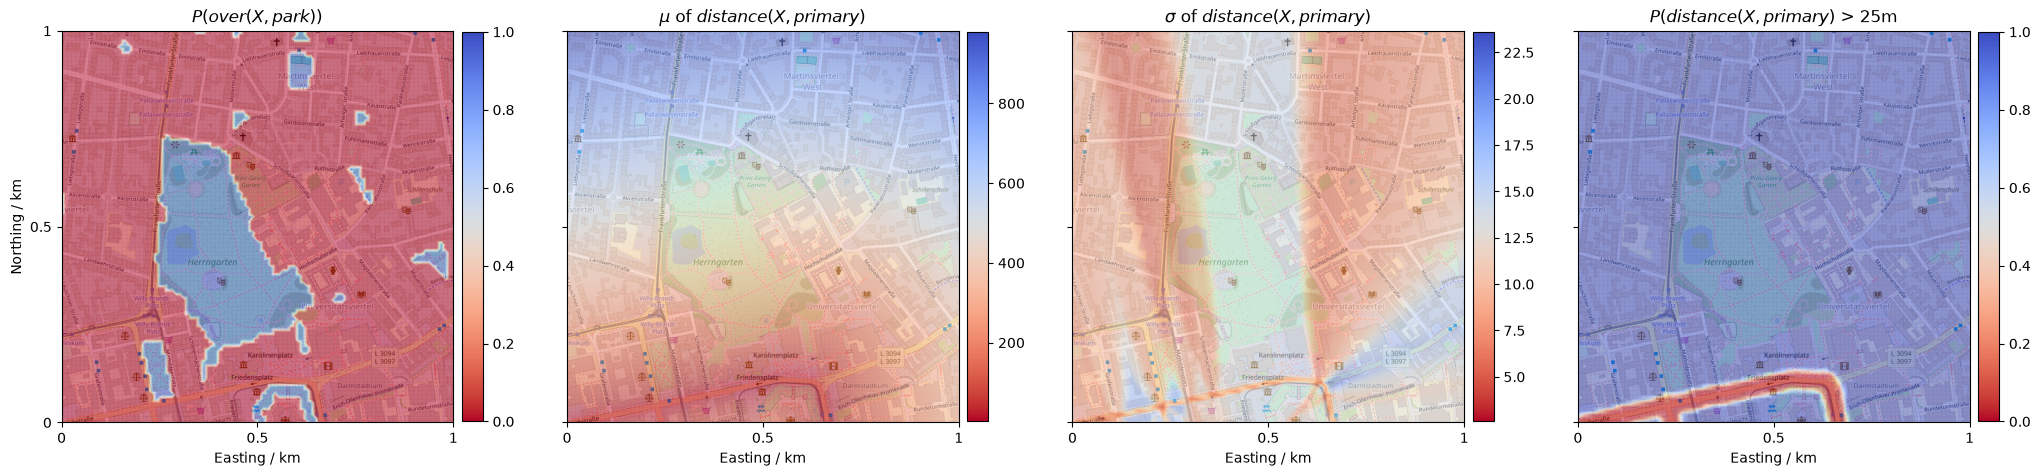

In [10]:
# Prepare the figure
fig, axes = plt.subplots(1, 4, sharey=True, figsize=(25, 10))

# We can query each relation from the StaR Map given its name and the location type it relates to
over_park = star_map.get("over", "park")
distance_primary = star_map.get("distance", "primary")

show_collection(over_park.parameters, 0, axes[0], r'$P(over(X, park))$')
show_collection(distance_primary.parameters, 0, axes[1], r'$\mu$ of $distance(X, primary)$')
show_collection(distance_primary.parameters, 1, axes[2], r'$\sigma$ of $distance(X, primary)$')
show_collection(distance_primary > 25, 0, axes[3], r'$P(distance(X, primary)$ > 25m')

# Show results
set_style(axes)
plt.show()

## Probabilistic Mission Design

We can now employ ProMis' core functionality: computing a Probabilistic Mission Landscape (PML).
A PML is a scalar field expressing at each point in the agent's state space how probable it is that all stated rules are satisfied.

`ProMis` takes the StaRMap, the Resin program, and the number of evaluation points.
Calling `initialize` writes all map-derived relation parameters into the reactive circuit, and `update` runs inference to produce the landscape.

In [11]:
# Evaluation raster for the mission landscape
resolution = (1000, 1000)
raster = CartesianRasterBand(origin, resolution, width, height)
dimension = resolution[0] * resolution[1]

# Compile the Resin program, wire StaRMap sources, and run inference
promis = ProMis(star_map, resin_program, dimension)
promis.initialize(raster)
landscape = promis.update()

Let's inspect the resulting landscape!
Blue regions indicate high probability of satisfying all constraints, and red areas should be avoided.

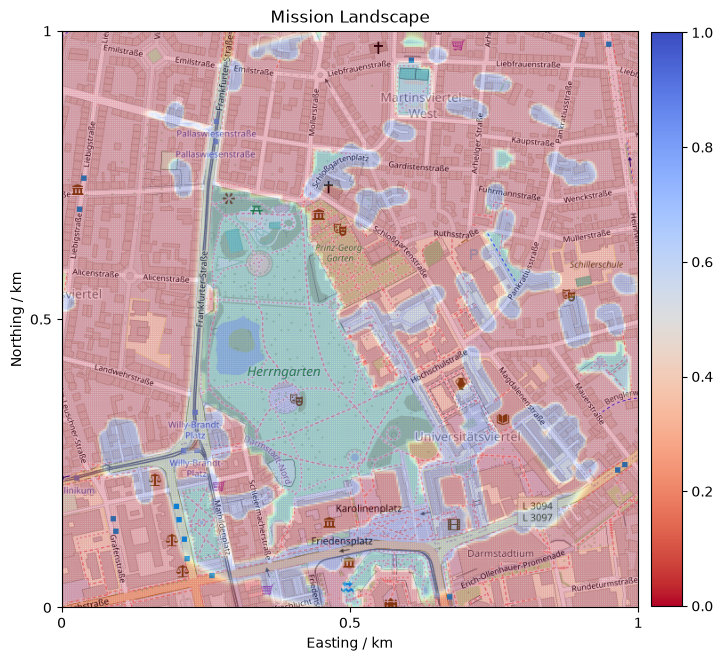

In [12]:
# Show the Probabilistic Mission Landscape
fig, ax = plt.subplots(1, 1, figsize=(8, 7.5))

show_collection(landscape, 0, ax, r'Mission Landscape')

set_style([ax])
plt.show()

## Streaming Updates

So far, the environment was static.
ProMis is built on [Resin](https://github.com/simon-kohaut/resin), whose reactive inference only recomputes the parts of the program whose inputs changed.
This lets the mission landscape follow live data, such as other drones flying through the mission area.

We extend our rules so that our agent keeps a safety distance of 75 m to other drones.
Their distance is a source like any other, but its values will be streamed in while the landscape is in use.

In [13]:
# Python Standard Library
import time

# Third Party dependencies for the simulation and its animation
import numpy as np
from numpy.random import default_rng, normal
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# The mission rules from before, where valid missions also keep their distance to other drones
streaming_program = resin_program.replace(
    "landscape if vlos and permits.",
    """distance(uas) <- source("/star_map/distance/uas", Density).
       agent_safety if distance(uas) > 75.0.
       
       landscape if vlos and permits and agent_safety.""",
)

We reuse the StaR Map of the static environment and set up a new ProMis instance for the extended rules, which computes the landscape on a finer raster.
Since the distances to other drones change much more often than the rest, we lift them to their own, more frequently updated part of Resin's reactive circuit.
Until the first positions arrive, the other drones are assumed to be far away.

A second StaR Map over a map of only the other drones is linked to ProMis, so that each of its updates is streamed into the landscape.

In [14]:
# Setup ProMis on the StaR Map of the static environment, with a finer raster for the landscape
landscape_raster = CartesianRasterBand(origin, (300, 300), width, height)
number_of_points = len(landscape_raster.data)
streaming_promis = ProMis(star_map, streaming_program, number_of_points)

# Lift the frequently changing distances to other drones
reactive_circuit = streaming_promis.get_reactive_circuit()
names = streaming_promis.get_names()
for interval in (0, 1):
    reactive_circuit.lift_leaf(names.index(f"u_distance_uas_{interval}"))

# Write the static relations, and initialize the distances to other drones as very far away
streaming_promis.initialize(landscape_raster)
streaming_promis.get_star_map_writer("distance", "uas").write(
    "normal", [[10_000.0] * number_of_points, [100.0] * number_of_points], time.monotonic()
)

# A StaR Map of the other drones, whose updates are streamed into ProMis
drone_uam = CartesianMap(origin)
drone_star_map = StaRMap(drone_uam)
drone_star_map.link(streaming_promis)

Now we simulate five drones flying between random waypoints at 10 m/s.
In each step of 2 seconds, we update the drones' StaR Map with their positions, which are uncertain by 10 m, and ask ProMis for the updated landscape.
The distances to the drones only need to be estimated where they change the landscape, so we estimate them at points scattered around each drone and interpolate onto the rest of the raster.
The points are spread wider than the safety radius, so that the interpolation between them stays beyond it away from the drones.

In [15]:
# Simulation settings
rng = default_rng(2024)
time_step = 2.0  # seconds
number_of_steps = 40
drone_speed = 10.0  # m/s

def random_waypoint():
    return (rng.random(2) - 0.5) * [width, height]

drones = [{"position": random_waypoint(), "destination": random_waypoint()} for _ in range(5)]

frames, update_durations = [], []
for step in range(number_of_steps):
    # Fly each drone towards its waypoint, and pick a new one on arrival
    for drone in drones:
        direction = drone["destination"] - drone["position"]
        distance = np.linalg.norm(direction)
        if distance < drone_speed * time_step:
            drone["position"] = drone["destination"]
            drone["destination"] = random_waypoint()
        else:
            drone["position"] = drone["position"] + direction / distance * drone_speed * time_step

    # Stream the drones' positions, each uncertain with a standard deviation of 10 m
    drone_uam.features = {"uas": [
        CartesianLocation(*drone["position"], location_type="uas", covariance=10.0**2 * eye(2)) for drone in drones
    ]}
    sample_points = CartesianCollection(origin)
    sample_points.append_with_default(np.vstack([normal(drone["position"], 100.0, [100, 2]) for drone in drones]), 0.0)
    drone_star_map.update(sample_points, 25, what={"distance": ["uas"]}, timestamp=time.monotonic())

    # Resin's writers deliver values asynchronously, so we give them a moment before the update
    time.sleep(0.05)
    started = time.perf_counter()
    landscape = streaming_promis.update()
    update_durations.append(time.perf_counter() - started)

    frames.append((step * time_step, landscape.values()[:, 0].reshape(landscape_raster.resolution[::-1]),
                   np.array([drone["position"] for drone in drones])))

print(f"Updating the landscape took {1000 * np.mean(update_durations):.1f} ms on average")

Updating the landscape took 7.5 ms on average


Finally, we animate the landscape over an OpenStreetMap basemap.
Use the controls below the figure to play the simulation or step through it.
Around each drone, a 75 m radius is avoided, which moves with the drones through the otherwise static landscape.

In [16]:
# Animate the landscape over an OpenStreetMap basemap, embedded in the notebook as HTML
plt.rcParams["animation.frame_format"] = "jpeg"  # keeps the embedded animation small
extent = (-width / 2, width / 2, -height / 2, height / 2)

fig, ax = plt.subplots(figsize=(6, 5.5), dpi=100)
ax.imshow(landscape_raster.to_polar().get_basemap(), extent=extent)
image = ax.imshow(frames[0][1], origin="lower", extent=extent, cmap="coolwarm_r", vmin=0, vmax=1, alpha=0.55)
drone_markers = ax.scatter([], [], marker="o", s=40, c="white", edgecolors="black", label="Other drones")
ax.legend(loc="upper left")
ax.set_xlabel("Easting / m")
ax.set_ylabel("Northing / m")
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.02)
title = ax.set_title("")

def draw(frame):
    seconds, values, drone_positions = frame
    image.set_data(values)
    drone_markers.set_offsets(drone_positions)
    title.set_text(f"t = {seconds:.0f} s")

animation = FuncAnimation(fig, draw, frames=frames, interval=200)
plt.close(fig)  # only show the animation, not the static figure
HTML(animation.to_jshtml())